# PDE 2 notebook

## Overrelaxation

The Laplace equation is common in Physics:

$$
\nabla^2 \phi = 0
$$

Using overrelaxation, we can define the next value of $\phi'(x,y)$ as:

$$
\phi'(x, y) = \frac{1+\omega}{4}\left[\phi(x+a,y) + \phi(x-a, y) + \phi(x, y+a) + \phi(x, y-a)\right] - \omega\phi(x,y)
$$

Every point is the average of the points around it modified by the term $\omega$. With this version of the solution, $\omega$ must be less than 1 for the method to converge.

In the example below, we consider the electric potential in a region of space of 1 m by 1 m mapped onto a 101x101 matrix. Hence, $a = 0.01$ m. Three sides of the box ($x = 0$, $x = 1$, and $y = 0$) are grounded with $\phi = 0$ V. On the last edge ($y = 1$), the voltage is defined as:

$$
\phi(x, 1) = 5\sin(2\pi x)
$$

We track the number of iterations needed for the system to converge depending on the value of $\omega$.

With omega = 0.0, system converged in 1180 iterations.
With omega = 0.1, system converged in 1025 iterations.
With omega = 0.2, system converged in 884 iterations.
With omega = 0.3, system converged in 757 iterations.
With omega = 0.4, system converged in 639 iterations.
With omega = 0.5, system converged in 528 iterations.
With omega = 0.6, system converged in 423 iterations.
With omega = 0.7, system converged in 321 iterations.
With omega = 0.8, system converged in 218 iterations.
With omega = 0.9, system converged in 102 iterations.


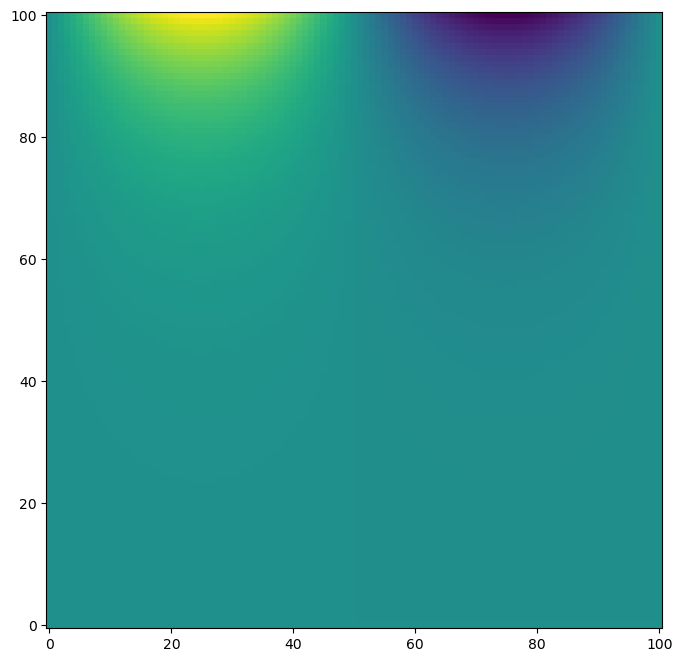

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
import sys

# Constants
N = 101
target = 1e-4
L = 1

# x axis
x = np.linspace(0, L, num = N, endpoint=True)

# Edge voltage
def edge(x):
    return 5*np.sin(2*np.pi*x)

def overrelax_red_black(x, N, target, omega=0.0, MAXIT = 2000):

    phi = np.zeros((N,N), dtype="float")
    phi[-1,:] = edge(x)

    counter = 0
    delta = 1
    
    while delta > target:
        delta = 0.0
        for parity in (0, 1):
            for i in range(1, N-1):
                # First interior j in row i with (i+j) % 2 == parity, then every second point
                for j in range(1 + (i + 1 + parity) % 2, N-1, 2):
                    new = -omega*phi[i,j] + (1+omega)*(phi[i+1,j]+phi[i-1,j]+phi[i,j+1]+phi[i,j-1])/4.0
                    delta = max(delta, abs(new - phi[i,j]))
                    phi[i,j] = new

        counter += 1

        if counter >= MAXIT:
            sys.exit(f"Did not converge in {MAXIT} iterations.")

    return phi, counter

# Run the relaxation
omega = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for o in omega:
    phi, counter = overrelax_red_black(x, N, target, omega = o)
    print(f"With omega = {o}, system converged in {counter} iterations.")

fig1, axes1 = plt.subplots(1,1,figsize=(8,8))
axes1.imshow(phi, origin='lower')
plt.show()

As mentioned above, the system only converges for $\omega < 1$. If we let it go above one, we get the code below.

In [23]:
phi, counter = overrelax_red_black(x, N, target, omega = 1.1)

SystemExit: Did not converge in 3000 iterations.

/usr/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3756: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Forward time centered space method

The FTCS method is a good method to solve the diffusion equation:
$$
\frac{\partial \phi}{\partial t} = D \frac{\partial^2 \phi}{\partial x^2}
$$

We express the right hand side in terms of numerical differentiation:
$$
\frac{\partial^2\phi}{\partial x^2} = \frac{\phi(x+a, t) - 2\phi(x,t) + \phi(x-a,t)}{a^2}
$$

With this, every point along the x-axis can be moved in time using the Euler method:
$$
\phi(x, t+h) = \phi(x,t) + \frac{hD}{a^2}\left[\frac{\phi(x+a, t) - 2\phi(x,t) + \phi(x-a,t)}{a^2}\right]
$$

This method can be used to track heat flow in a solid. In the example below, we track how the temperature evolves in a bar of metal that is insulated along its length with one end exposed to a 0.0 degC bath and the other a 50.0 degC bath. The bar is 1 cm long. Assume the metal is steel with $D = 4.25\times10^{-6}$ $m^2$ $s^{-1}$. Assume that the bar starts at 15 degC everywhere. Because the bar in insulated, there is no heat exchange along the length, only at the ends. We let the bar evolves over 10 seconds.

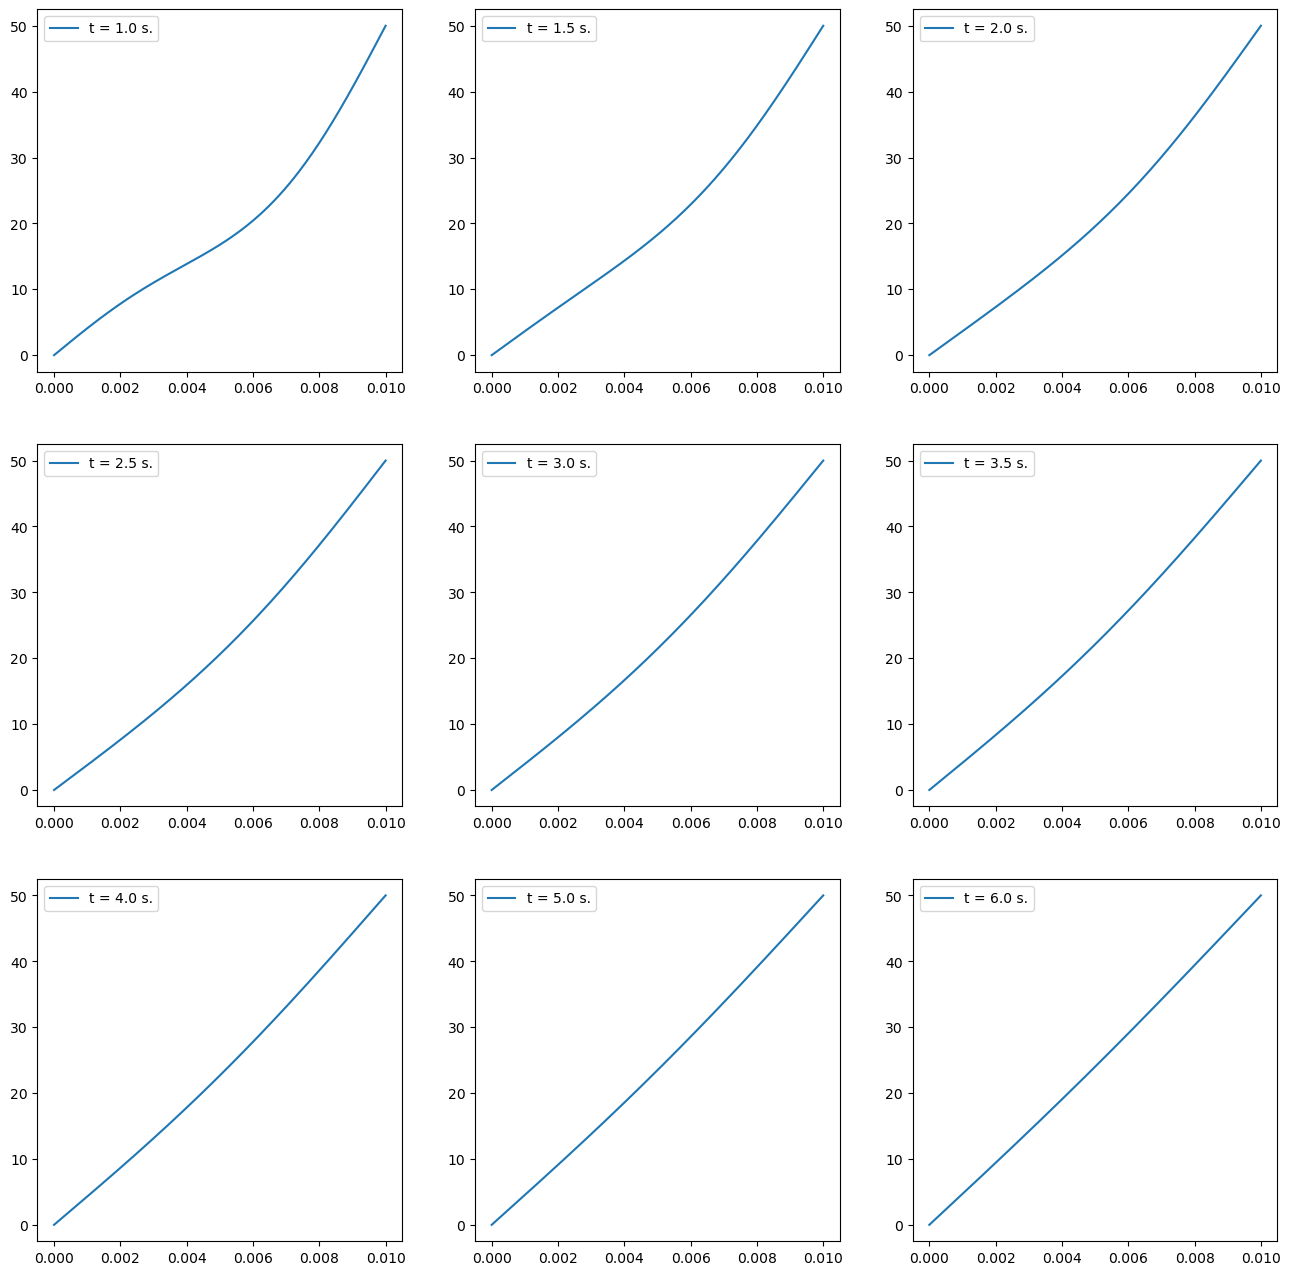

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 

# Constants
L = 0.01
D = 4.25e-6
N = 200
a = L/N
h = 1e-4 
T1 = 0.0
Tmid = 15.0    # Temperature of the rod before making contact
T2 = 50.0 
t_max = 6.0
epsilon = h/1000.

# Create temperature array with init temp at Tmid degC
T = Tmid*np.ones(N, dtype="float")
# Fix the end of the temperature array
T[0] = T1
T[-1] = T2 
Tprime = np.copy(T)

# x axis
x = np.linspace(0, L, num=N)

# Constants for the loop
t = 0.0
c = h*D/a**2

times_pict = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
counter_pict = 0

fig2, axes2 = plt.subplots(3,3, figsize=(16,16))

while t < t_max:
    for i in range(1, N-1):
        Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])

    T, Tprime = Tprime, T

    if counter_pict<len(times_pict):
        if np.abs(t-times_pict[counter_pict])<epsilon:
            i = counter_pict // 3
            j = counter_pict % 3
            axes2[i,j].plot(x, T, label=f"t = {times_pict[counter_pict]} s.")
            axes2[i,j].legend(loc='upper left')
            counter_pict += 1

    t += h

plt.show()

## Numerical stability

For the diffusion equation, the condition on stability is:
$$
h \leq \frac{a^2}{2D}
$$

In the system above, we have:
- $a = 0.01/200 = 5\times10^{-5}$ m
- $D = 4.25\times10^{-6}$

This results in a value of $h \leq 5.9\times10^{-4}$. We selected $h = 10^{-4}$ which is in the stability region. If we repeat the simulation above with $h=10^{-3}$, we get the results below.

/tmp/ipykernel_433026/1809420584.py:37: RuntimeWarning: overflow encountered in scalar multiply
  Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])
/tmp/ipykernel_433026/1809420584.py:37: RuntimeWarning: overflow encountered in scalar add
  Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])
/tmp/ipykernel_433026/1809420584.py:37: RuntimeWarning: overflow encountered in scalar subtract
  Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])
/tmp/ipykernel_433026/1809420584.py:37: RuntimeWarning: invalid value encountered in scalar add
  Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])


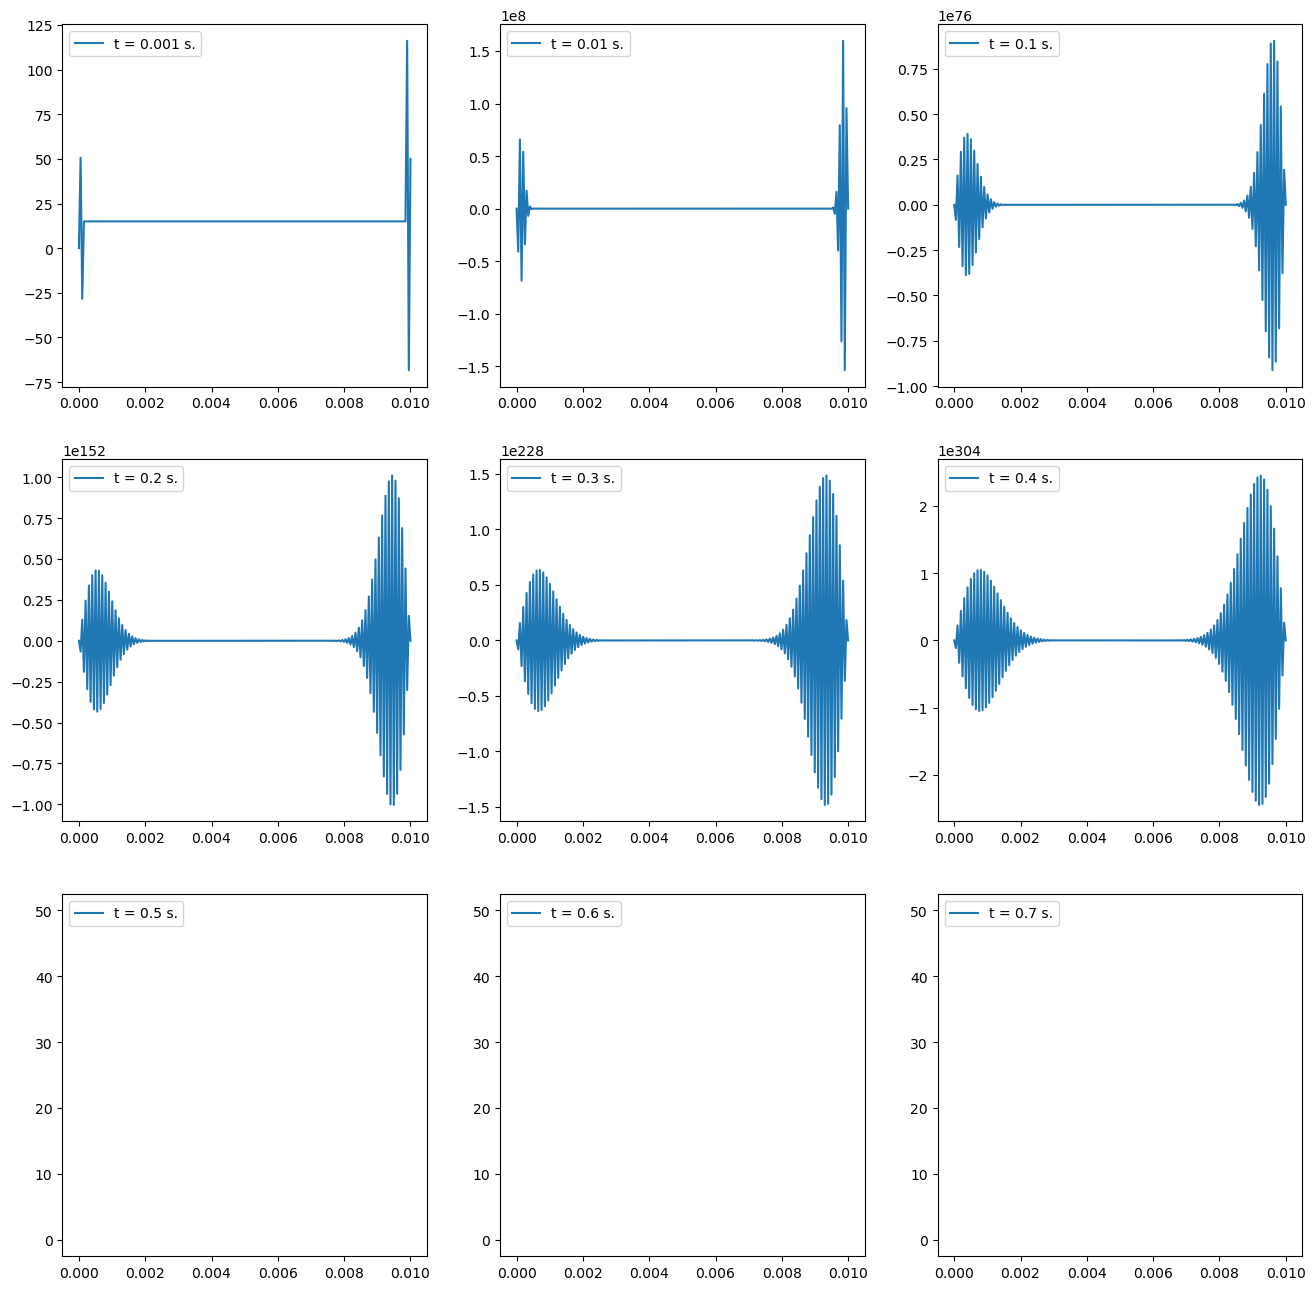

In [48]:
import numpy as np 
import matplotlib.pyplot as plt 

# Constants
L = 0.01
D = 4.25e-6
N = 200
a = L/N
h = 1e-3
T1 = 0.0
Tmid = 15.0    # Temperature of the rod before making contact
T2 = 50.0 
t_max = 1.0
epsilon = h/1000.

# Create temperature array with init temp at 25.0 degC
T = Tmid*np.ones(N, dtype="float")
# Fix the end of the temperature array
T[0] = T1
T[-1] = T2 
Tprime = np.copy(T)

# x axis
x = np.linspace(0, L, num=N)

# Constants for the loop
t = 0.0
c = h*D/a**2

times_pict = [0.001, 0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
counter_pict = 0

fig2, axes2 = plt.subplots(3,3, figsize=(16,16))

while t < t_max:
    for i in range(1, N-1):
        Tprime[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])

    T, Tprime = Tprime, T

    if counter_pict<len(times_pict):
        if np.abs(t-times_pict[counter_pict])<epsilon:
            i = counter_pict // 3
            j = counter_pict % 3
            axes2[i,j].plot(x, T, label=f"t = {times_pict[counter_pict]} s.")
            axes2[i,j].legend(loc='upper left')
            counter_pict += 1

    t += h

plt.show()


A single step gives the wrong answer the instability grows until the solution runs out of range for float representation.